# Kesit İstatistik — Eksik veri ve anket çıkarımı

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Çoklu atama ve eksik veri belirsizliği

Tek atama belirsizliği neden eksik gösterir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Ayrı sonsal çekimlerle tamamlanmış veri setlerinin eğimlerini karşılaştır.

**Yorum sınırı:** IterativeImputer+BayesianRidge sayısal MAR örneğidir; MNAR ve kategorik alanlar ayrıca modellenmeli.

**Alıştırma:** Eksik payını %25’ten %50’ye çıkar; Rubin toplam varyansındaki payları karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'havuz_egim': np.float64(2.214864798684707), 'ic_varyans': np.float64(0.005447452379679036), 'arasi_varyans': np.float64(0.00035168531318430034), 'Rubin_SE': np.float64(0.07638263038271048)}


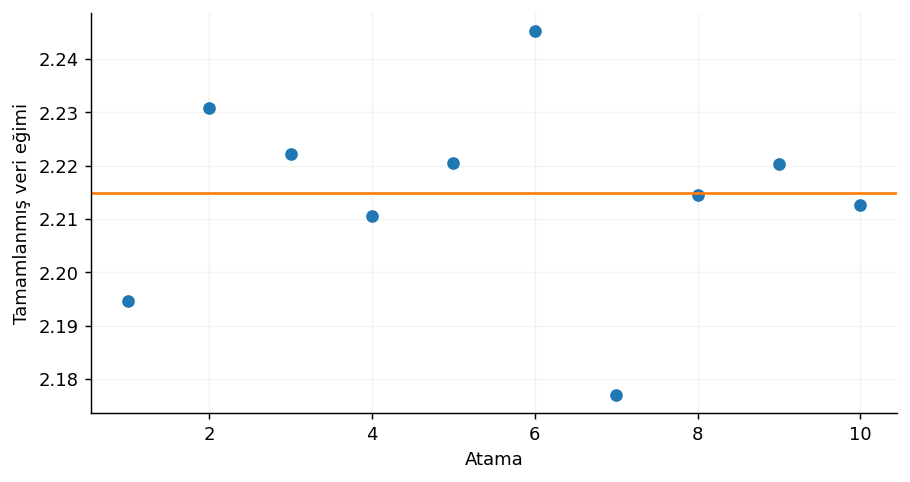

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
x=rng.normal(size=250);z=.6*x+rng.normal(size=250);y=1+2*x+z+rng.normal(size=250);data=np.c_[x,z,y];mask=rng.uniform(size=250)<.25;data[mask,0]=np.nan;est=[];vars=[]
for seed in range(10):
 complete=IterativeImputer(estimator=BayesianRidge(),sample_posterior=True,random_state=seed,max_iter=10).fit_transform(data);fit=sm.OLS(complete[:,2],sm.add_constant(complete[:,:2])).fit();est.append(fit.params[1]);vars.append(fit.cov_params()[1,1])
within=np.mean(vars);between=np.var(est,ddof=1);total=within+1.1*between;print({'havuz_egim':np.mean(est),'ic_varyans':within,'arasi_varyans':between,'Rubin_SE':np.sqrt(total)})
plt.plot(range(1,11),est,'o');plt.axhline(np.mean(est),c='tab:orange');plt.xlabel('Atama');plt.ylabel('Tamamlanmış veri eğimi')

## Anket ağırlıkları ve etkin örneklem

Ağırlıklı anketin 100 kaydı gerçekten 100 birim bilgi mi?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Ağırlık yoğunlaştıkça Kish etkin örneklemin düşmesini izle.

**Yorum sınırı:** Kish ESS tek başına tasarım varyansı değildir; küme/katman/FPC için tam anket tasarımı gerekir.

**Alıştırma:** Son ağırlığı 15’ten 50’ye çıkar; ağırlıklı ortalama ve ESS’yi birlikte raporla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'agirlikli_ortalama': np.float64(9.885769152906457), 'ham_n': 100, 'Kish_ESS': np.float64(40.111111111111114), 'yalniz_agirlik_DEFF': np.float64(2.493074792243767)}


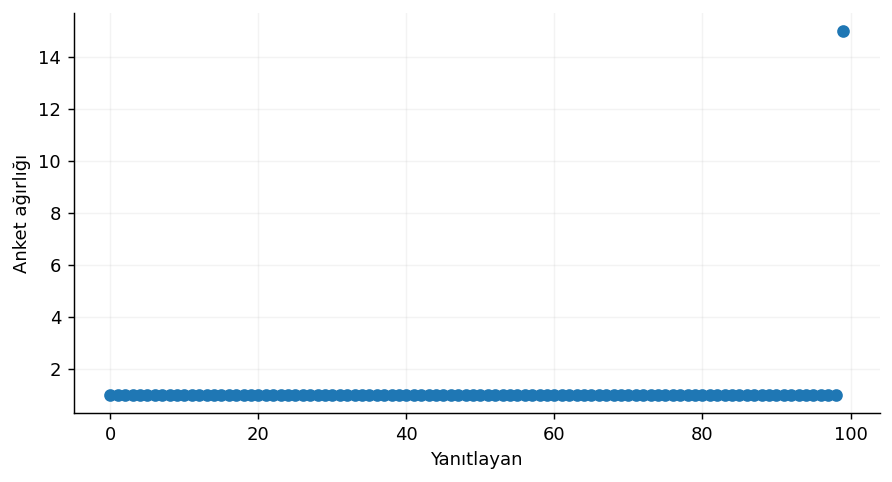

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

y=rng.normal(10,2,100);w=np.r_[np.ones(99),15.];estimate=np.average(y,weights=w);ess=w.sum()**2/(w@w);print({'agirlikli_ortalama':estimate,'ham_n':len(y),'Kish_ESS':ess,'yalniz_agirlik_DEFF':len(y)/ess})
plt.plot(w,'o');plt.xlabel('Yanıtlayan');plt.ylabel('Anket ağırlığı')

## Ölçüm hatası ve regresyona dönüş

Gürültülü ölçüm ilişkiyi nasıl zayıflatır?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı yanıt için gerçek ve hatalı x eğimlerini karşılaştır.

**Yorum sınırı:** Klasik bağımsız ölçüm hatası senaryosu; gerçek hayatta hata yapısı ve tekrar ölçümler ayrıca gerekir.

**Alıştırma:** Ölçüm hata sapmasını 1.5’ten .2’ye indir; zayıflamayı incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'gercek_x_egim': np.float64(3.0056697818898734), 'hata_x_egim': np.float64(0.8584989199148481), 'secili_ilk_ortalama': np.float64(2.561208675472453), 'secili_tekrar_ortalama': np.float64(1.364782153169744)}


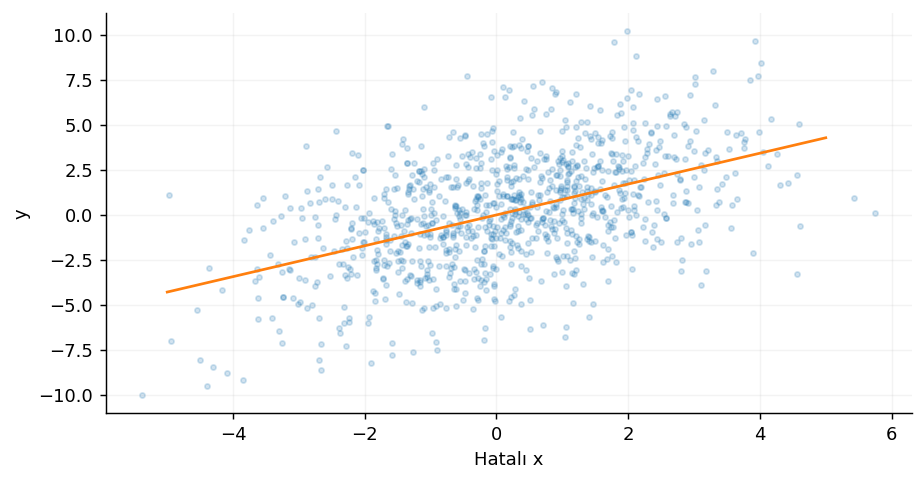

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.normal(size=1000);y=3*x+rng.normal(size=1000);xm=x+rng.normal(0,1.5,len(x));btrue=stats.linregress(x,y).slope;bmeas=stats.linregress(xm,y).slope
baseline=rng.normal(size=1000);first=baseline+rng.normal(size=1000);second=baseline+rng.normal(size=1000);selected=first>np.quantile(first,.9)
print({'gercek_x_egim':btrue,'hata_x_egim':bmeas,'secili_ilk_ortalama':first[selected].mean(),'secili_tekrar_ortalama':second[selected].mean()})
plt.scatter(xm,y,s=8,alpha=.2);grid=np.linspace(-5,5,50);plt.plot(grid,bmeas*grid,c='tab:orange');plt.xlabel('Hatalı x');plt.ylabel('y')

## Duyarlılık analizi ve yeniden üretilebilirlik

Varsayım değişince kararım ayakta kalıyor mu?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Eksiklerin gözlenenlerden farklı olabileceği senaryoları karşılaştır.

**Yorum sınırı:** Bu delta duyarlılığı MNAR’ı teşhis etmez; makul aralığı alan bilgisi belirler.

**Alıştırma:** Delta aralığını ±2 yerine ±5 yap; karar eşiği 10’a göre sonucu yaz.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


   delta  tam_ortalama
0   -2.0      9.930957
1   -1.5     10.030957
2   -1.0     10.130957
3   -0.5     10.230957
4    0.0     10.330957
5    0.5     10.430957
6    1.0     10.530957
7    1.5     10.630957
8    2.0     10.730957
Veri SHA256: 0d243d3fc030e418ff8e457d21b14f6ba3473e28eefcf58e6f115d853dd230ae


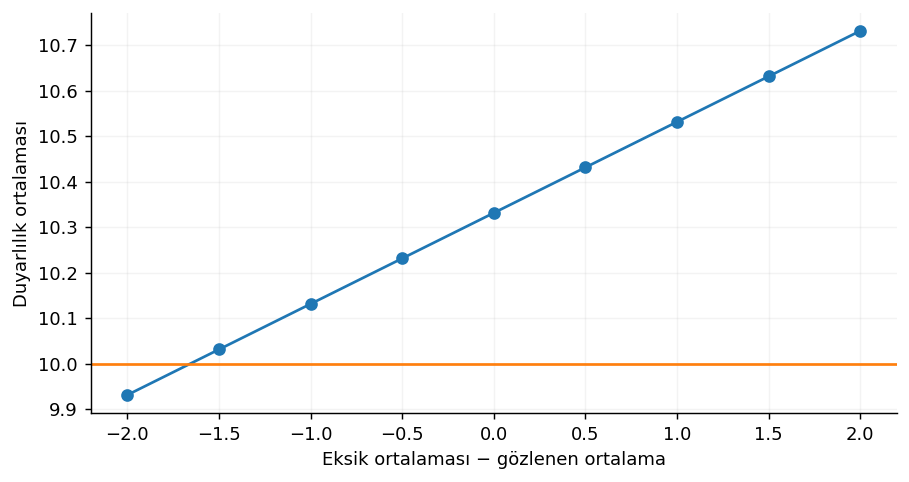

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

import hashlib
observed=rng.normal(10,2,80);missing_n=20;deltas=np.linspace(-2,2,9);means=[(observed.sum()+missing_n*(observed.mean()+d))/(len(observed)+missing_n) for d in deltas]
print(pd.DataFrame({'delta':deltas,'tam_ortalama':means}));print('Veri SHA256:',hashlib.sha256(observed.tobytes()).hexdigest());plt.plot(deltas,means,'o-');plt.axhline(10,c='tab:orange');plt.xlabel('Eksik ortalaması − gözlenen ortalama');plt.ylabel('Duyarlılık ortalaması')